# Telco Customer Churn — analiza i przewidywanie odejść klientów

1. Cel projektu

Celem projektu jest analiza danych klientów firmy telekomunikacyjnej oraz sprawdzenie, czy na podstawie dostępnych informacji można przewidywać odejście klienta (customer churn).

Projekt obejmuje analizę eksploracyjną danych (EDA), przygotowanie danych do modelowania, budowę modeli klasyfikacyjnych oraz ocenę ich skuteczności.

2. Pytanie badawcze

Czy wybrane cechy klientów i warunki korzystania z usług telekomunikacyjnych mogą pomóc zidentyfikować klientów, którzy rezygnują z usług?

3. Zbiór danych

W projekcie wykorzystano zbiór Telco Customer Churn udostępniony na platformie Kaggle.

Źródło danych: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Dane zawierają informacje o klientach, używanych przez nich usługach, rodzaju umowy i opłatach. Kolumna Churn informuje, czy klient zrezygnował z usług.

4. Plan pracy

- Wczytanie danych i sprawdzenie ich struktury.

- Ocena jakości danych i przygotowanie ich do analizy.

- Analiza eksploracyjna oraz identyfikacja zależności między cechami klientów a odejściami.

- Przygotowanie danych i budowa modeli klasyfikacyjnych.

- Ocena wyników modeli, porównanie ich z modelem bazowym oraz wybór modelu najlepiej odpowiadającego potrzebom biznesowym.

- Sformułowanie wniosków i rekomendacji biznesowych.

5. Oczekiwany rezultat

Rezultatem projektu będzie działający proces analizy danych i modelowania oraz wnioski biznesowe poparte wynikami analizy.

6. Użyte oprogramowanie i sposób dostarczenia projektu

Projekt napisany w Visual Studio Code, wysłany na repozytorium GitHub.

-------------

## **Wczytanie, ocena i przygotowanie danych do analizy**

### **Import bibliotek i konfiguracja środowiska**

Do analizy danych i przygotowania wizualizacji wykorzystane zostaną następujące biblioteki:

- **Pandas** — wczytywanie, przetwarzanie i analiza danych tabelarycznych.
- **NumPy** — operacje numeryczne.
- **Matplotlib** — tworzenie wykresów.
- **Seaborn** — tworzenie wykresów statystycznych.
- **Scikit-learn** — przygotowanie danych, budowa modeli klasyfikacyjnych i ocena ich wyników; biblioteka zostanie zaimportowana na etapie preprocessingu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

### **Wczytanie zbioru danych**

Dane zapisane w pliku CSV zostaną wczytane do obiektu *Pandas Dataframe*, czyli tabeli umożliwiającej dalszą analizę.

Ścieżka do zbioru danych zostanie określona względnie względem struktury katalogów projektu, tak aby ułatwić uruchomienie notebooka na innym komputerze.

Przed wczytaniem zostanie sprawdzone, czy plik znajduje się
w oczekiwanym katalogu projektu.

Po wczytaniu danych zostaną wyświetlone pierwsze rekordy,
aby sprawdzić, czy plik został odczytany prawidłowo.

In [2]:
# Ustalenie katalogu projektu
PROJECT_DIR = Path.cwd()

# Jeśli w bieżącym katalogu nie ma folderu data,
# sprawdzenie katalogu nadrzędnego
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent

# Ścieżka do pliku CSV
DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Sprawdzenie, czy plik istnieje
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Nie znaleziono pliku danych: {DATA_PATH}"
    )

# Wczytanie danych do tabeli
df = pd.read_csv(DATA_PATH)

# Wyświetlenie pierwszych pięciu rekordów
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Wstępna kontrola danych**

W celu poznania struktury zbioru sprawdzone zostaną: liczba wierszy i kolumn, nazwy kolumn, typy danych oraz liczbę niepustych wartości w poszczególnych kolumnach.

Kontrola ta pozwoli wstępnie ocenić, czy dane wymagają dodatkowego przygotowania przed analizą.

In [3]:
# Liczba wierszy i kolumn
print("Rozmiar zbioru:", df.shape)

# Informacje o kolumnach i typach danych
df.info()

Rozmiar zbioru: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non

##### **Uwaga**

Tu warto zwrócić uwagę na fakt, że kolumna `MonthlyCharges`, zawierająca opłaty miesięczne, ma typ liczbowy `float64`. Kolumna `TotalCharges`, zawierająca opłaty łączne, została wczytana jako tekst (`str`).

Aby umożliwić wykonywanie obliczeń na tej kolumnie, konieczna jest konwersja jej zawartości na typ liczbowy.

#### **Kontrola jakości danych**

Przed rozpoczęciem analizy należy sprawdzić, czy zbiór zawiera brakujące wartości i powtarzające się rekordy.

Brakujące dane mogą utrudniać analizę, a duplikaty mogą wpływać na uzyskane wyniki. Dodatkowo zostanie sprawdzona liczba klientów, którzy zrezygnowali z usług.

Wyniki tej kontroli pomogą ustalić, czy dane wymagają dalszego przygotowania.

In [4]:
# Sprawdzenie brakujących wartości
print("Brakujące wartości w kolumnach:")
print(df.isnull().sum())

# Sprawdzenie liczby zduplikowanych wierszy
print("\nLiczba zduplikowanych wierszy:")
print(df.duplicated().sum())

# Sprawdzenie liczby klientów w każdej kategorii Churn
print("\nLiczba klientów według Churn:")
print(df["Churn"].value_counts())

Brakujące wartości w kolumnach:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Liczba zduplikowanych wierszy:
0

Liczba klientów według Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Kolumna `TotalCharges` została wczytana jako typ tekstowy (`str`), dlatego przed dalszą analizą należy przekształcić ją na typ liczbowy. Następnie zostanie sprawdzone, czy konwersja ujawniła brakujące wartości.

In [5]:
# Konwersja TotalCharges na wartości liczbowe
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Sprawdzenie brakujących wartości po konwersji
print("Brakujące wartości w TotalCharges:")
print(df["TotalCharges"].isnull().sum())

# Wyświetlenie rekordów z brakującą wartością TotalCharges
df.loc[
    df["TotalCharges"].isnull(),
    ["tenure", "TotalCharges", "Churn"]
]

Brakujące wartości w TotalCharges:
11


,tenure,TotalCharges,Churn
488,0,NaN,No
753,0,NaN,No
936,0,NaN,No
1082,0,NaN,No
1340,0,NaN,No
3331,0,NaN,No
3826,0,NaN,No
4380,0,NaN,No
5218,0,NaN,No
6670,0,NaN,No


#### **Przygotowanie kolumny `TotalCharges`**

Dodatkowa kontrola wykazała 11 pustych wartości w kolumnie `TotalCharges`. Po wyświetleniu wszystkich wybrakowanych wpisów można zauważyć, że wszystkie dotyczyły klientów ze stażem wynoszącym 0.

Brakujące wartości zostaną uzupełnione zerami, zgodnie z przyjętym założeniem, że dla tych rekordów łączne opłaty wynoszą 0.

In [6]:
# Uzupełnienie brakujących wartości zerami
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Kontrola wyniku
print("Brakujące wartości w całym zbiorze:")
print(df.isnull().sum().sum())

print("\nTyp danych TotalCharges:")
print(df["TotalCharges"].dtype)

Brakujące wartości w całym zbiorze:
0

Typ danych TotalCharges:
float64


### **Wyniki wstępnej kontroli danych**

Zbiór zawiera 7043 rekordy i 21 kolumn. Początkowa kontrola nie wykazała brakujących wartości rozpoznawanych przez Pandas ani identycznych zduplikowanych wierszy.

Konwersja `TotalCharges` na typ liczbowy ujawniła 11 brakujących wartości. Wszystkie dotyczyły klientów ze stażem `tenure = 0` i wartością `Churn = No`. Braki uzupełniono zerami zgodnie z przyjętym założeniem.

Po uzupełnieniu braków zbiór nie zawiera brakujących wartości ani identycznych zduplikowanych wierszy. Dane są przygotowane do eksploracyjnej analizy danych (EDA).

-------------

## **Analiza eksploracyjna danych (EDA)**

Analiza eksploracyjna służy do poznania rozkładów zmiennych i zbadania zależności, które mogą być istotne dla przewidywania odejść klientów.

W pierwszej kolejności przeanalizowany zostanie rozkład zmiennej `Churn`, określającej, czy klient zrezygnował z usług. Pozwoli to ocenić udział odejść w zbiorze oraz sprawdzić, czy liczebność obu klas jest zrównoważona.

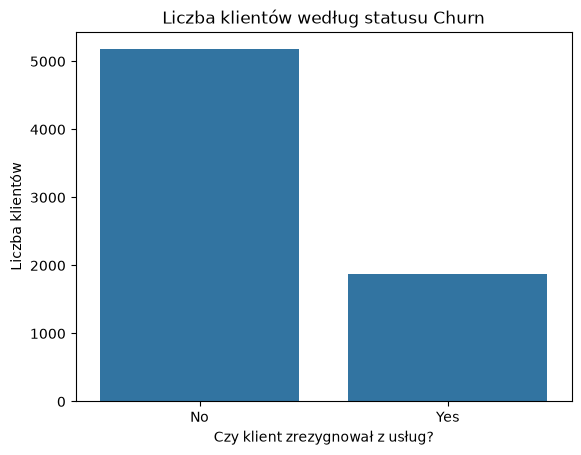

Udział klientów według Churn (%):
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [7]:
# Wykres liczby klientów według Churn
sns.countplot(data=df, x="Churn")

plt.title("Liczba klientów według statusu Churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Liczba klientów")
plt.show()

# Udział procentowy obu grup
print("Udział klientów według Churn (%):")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(1)
)

### Rozkład zmiennej docelowej 'Churn' - obserwacje

Analiza zmiennej docelowej wykazała, że 73,5% klientów pozostało przy usługach operatora (`No`), natomiast 26,5% zrezygnowało z usług (`Yes`).

Oznacza to, że klasy nie są zrównoważone. Model przewidujący wyłącznie brak rezygnacji mógłby osiągnąć accuracy na poziomie około 73,5%, nie identyfikując żadnego klienta odchodzącego.

Dlatego przy ocenie modeli istotne będą nie tylko accuracy, lecz także recall i F1-score dla klasy Yes oraz ROC-AUC. Metryki te pozwolą lepiej ocenić zdolność modeli do identyfikowania klientów odchodzących.

### Przegląd cech zbioru danych

W tej części zostanie przeprowadzony przegląd cech opisujących klientów oraz wykorzystywane przez nich usługi. Celem jest poznanie rozkładów danych, liczebności kategorii i potencjalnych zależności ze zmienną docelową `Churn`.

Kolumna `customerID` pełni funkcję identyfikatora, natomiast `Churn` jest zmienną docelową. Pozostałe kolumny będą rozpatrywane jako potencjalne cechy wejściowe modelu.

In [8]:

# Przegląd cech zbioru danych
feature_overview = pd.DataFrame({
    "Typ danych": df.dtypes.astype(str),
    "Liczba unikalnych wartości": df.nunique(),
    "Liczba braków": df.isnull().sum()
})

display(feature_overview)

,Typ danych,Liczba unikalnych wartości,Liczba braków
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


#### Przegląd cech liczbowych zbioru danych

Dodatkowo, dla cech liczbowych (tenure, MonthlyCharges, TotalCharges) zostaną obliczone statystyki opisowe, obejmujące m.in. średnią, odchylenie standardowe, medianę, kwartyle oraz wartości minimalne i maksymalne. Pozwoli to wstępnie ocenić rozkład wartości i zróżnicowanie poszczególnych zmiennych.

In [9]:

# Cechy liczbowe
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

display(df[numeric_cols].describe().round(2))

# Liczebność kategorii w pozostałych cechach
categorical_cols = [
    col for col in df.columns
    if col not in ["customerID", "Churn"]
    and (
        df[col].dtype == "object"
        or df[col].dtype == "str"
        or col == "SeniorCitizen"
    )
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtec

### **Analiza zmiennych numerycznych (`tenure`, `MonthlyCharges`, `TotalCharges`) względem Churn**

W celu porównania klientów, którzy zrezygnowali z usług, z klientami pozostającymi zostaną przedstawione rozkłady stażu oraz opłat miesięcznych i łącznych. Zostaną obliczone kwartyle dla stażu klienta (tenure), opłat miesięcznych (MonthlyCharges) i łącznych (TotalCharges) w grupie klientów, którzy zrezygnowali z usług. Do wizualizacji zostaną wykorzystane wykresy pudełkowe, które uzupełnią analizę - ułatwią porównanie median i zróżnicowania wartości w obu grupach.

In [10]:
# Kwartyle dla wybranych zmiennych wśród klientów, którzy odeszli

for column in ["tenure", "MonthlyCharges", "TotalCharges"]:
    values = df.loc[df["Churn"] == "Yes", column].dropna().to_numpy()

    q1, median, q3 = np.percentile(values, [25, 50, 75])

    print(f"\n{column}:")
    print(f"  I kwartyl:   {q1:.2f}")
    print(f"  Mediana:     {median:.2f}")
    print(f"  III kwartyl: {q3:.2f}")


tenure:
  I kwartyl:   2.00
  Mediana:     10.00
  III kwartyl: 29.00

MonthlyCharges:
  I kwartyl:   56.15
  Mediana:     79.65
  III kwartyl: 94.20

TotalCharges:
  I kwartyl:   134.50
  Mediana:     703.55
  III kwartyl: 2331.30


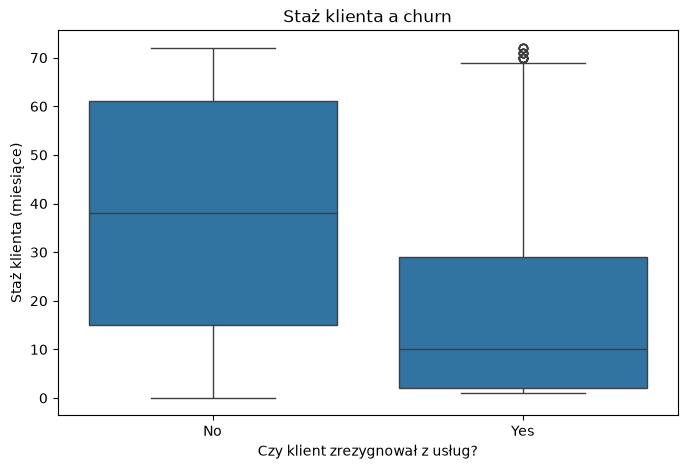

In [11]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Staż klienta a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Staż klienta (miesiące)")
plt.show()


##### `tenure` a churn - wniosek 
Klienci, którzy zrezygnowali z usług, mieli na ogół krótszy staż niż klienci pozostający. Mediana stażu wynosi około 10 miesięcy dla grupy `Churn = Yes` i około 38 miesięcy dla `Churn = No`. Sugeruje to, że początkowy okres relacji z klientem może być istotny w analizie churnu.

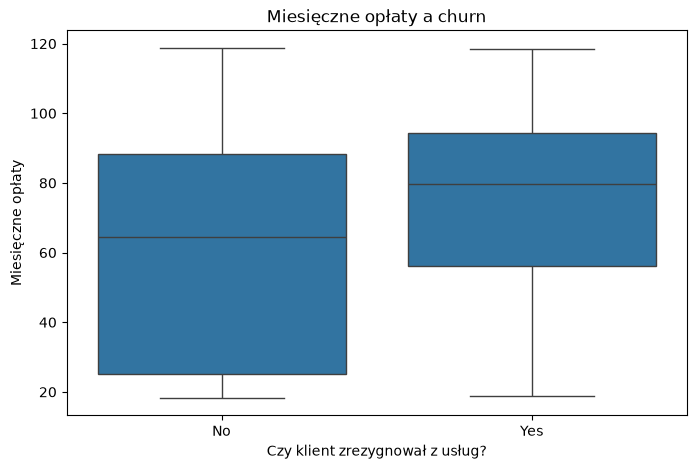

In [12]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Miesięczne opłaty a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Miesięczne opłaty")
plt.show()

##### `MonthlyCharges` a churn - wniosek

Klienci, którzy zrezygnowali z usług, mieli na ogół wyższe miesięczne opłaty niż klienci pozostający. Mediana `MonthlyCharges` wynosi około 80 dla grupy `Churn = Yes` i około 64–65 dla `Churn = No`. Rozkłady częściowo się pokrywają, dlatego wysokość opłat nie stanowi samodzielnego wyjaśnienia churnu.

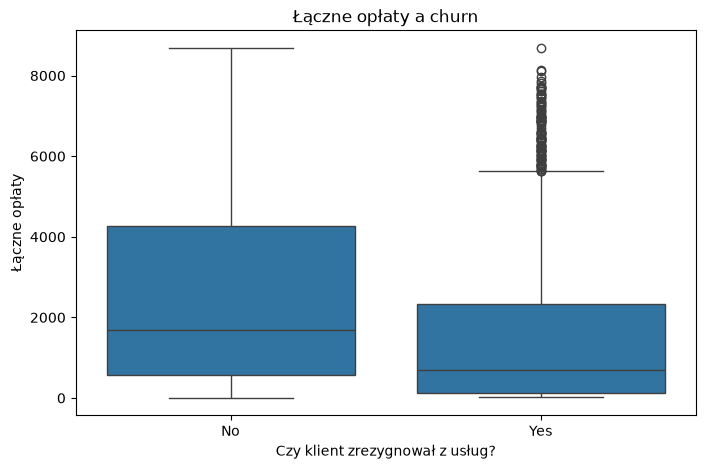

In [13]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Łączne opłaty a churn")
plt.xlabel("Czy klient zrezygnował z usług?")
plt.ylabel("Łączne opłaty")
plt.show()


#### `TotalCharges` a churn - wniosek

Klienci, którzy zrezygnowali z usług, mieli na ogół niższe łączne opłaty (`TotalCharges`) niż klienci pozostający. Mediana jest wyraźnie niższa w grupie `Churn = Yes`. Wynik należy interpretować z uwzględnieniem stażu klienta (`tenure`), ponieważ łączne opłaty zależą zarówno od wysokości opłat miesięcznych, jak i długości korzystania z usług.

### **Analiza zmiennych kategorycznych względem Churn**

Dla poszczególnych kategorii zostanie policzona liczba klientów oraz odsetek rezygnacji z usług. Pozwoli to porównać częstość churnu między grupami klientów.

In [14]:

for col in categorical_cols:
    summary = pd.DataFrame({
        "Liczebność": df.groupby(
            col, dropna=False
        )["Churn"].size(),

        "Churn (%)": (
            df.groupby(col, dropna=False)["Churn"]
            .apply(lambda x: (x == "Yes").mean() * 100)
        )
    })

    print(f"\n--- {col} ---")
    display(summary.round(1))


--- gender ---


,Liczebność,Churn (%)
gender,,
Female,3488,26.9
Male,3555,26.2



--- SeniorCitizen ---


,Liczebność,Churn (%)
SeniorCitizen,,
0,5901,23.6
1,1142,41.7



--- Partner ---


...

,Liczebność,Churn (%)
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8



--- PaperlessBilling ---


,Liczebność,Churn (%)
PaperlessBilling,,
No,2872,16.3
Yes,4171,33.6



--- PaymentMethod ---


,Liczebność,Churn (%)
PaymentMethod,,
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2
Electronic check,2365,45.3
Mailed check,1612,19.1


### Wnioski z przeglądu cech kategorycznych

Wstępna analiza wykazała wyraźne różnice w odsetku churnu pomiędzy wybranymi kategoriami. Największy odsetek odejść odnotowano wśród klientów z umową miesięczną (42,7%) oraz korzystających z elektronicznego czeku jako metody płatności (45,3%). Podwyższony churn zaobserwowano również wśród klientów korzystających ze światłowodu (41,9%) oraz nieposiadających usług OnlineSecurity (41,8%) i TechSupport (41,6%).

Niższy odsetek churnu występował m.in. wśród klientów z umowami dwuletnimi (2,8%) oraz posiadających usługi OnlineSecurity (14,6%) i TechSupport (15,2%). Widoczne były także różnice związane z obecnością partnera lub osób na utrzymaniu.

Nie wszystkie cechy wykazywały równie wyraźne różnice, np. odsetki churnu dla obu kategorii zmiennej gender były zbliżone (26,9% i 26,2%).

Wyniki mają charakter opisowy i nie wskazują na związki przyczynowe. Poszczególne cechy mogą być ze sobą powiązane, dlatego ich znaczenie należy ocenić również na etapie modelowania.

### **Podsumowanie EDA i wybór cech do dalszej analizy**

Przeprowadzona analiza eksploracyjna pozwoliła wskazać cechy, których kategorie różnią się pod względem odsetka rezygnacji klientów. Obserwacje te wskazują, które zależności warto uwzględnić na dalszych etapach projektu.

**Cechy i zależności wytypowane do dalszej obserwacji:**

- **`Contract`** — klienci z umowami miesięcznymi częściej rezygnowali z usług niż klienci z umowami długoterminowymi.
- **`tenure`** — klienci odchodzący mieli na ogół krótszy staż.
- **`MonthlyCharges` i `TotalCharges`** — zaobserwowano różnice w opłatach między klientami odchodzącymi a pozostającymi; łączne opłaty należy interpretować z uwzględnieniem stażu.
- **`InternetService`, `TechSupport` i `OnlineSecurity`** — odsetek churnu różnił się w zależności od rodzaju internetu i dostępności wybranych usług.
- **`PaymentMethod`** — najwyższy odsetek odejść odnotowano wśród klientów płacących elektronicznym czekiem.

Wybór ten opiera się na obserwowanych różnicach w danych i służy ukierunkowaniu dalszej interpretacji wyników. Na obecnym etapie nie oznacza to jednak, że wymienione cechy powodują rezygnację ani że są już potwierdzonymi predyktorami modelu.

Na etapie modelowania do zbioru cech wejściowych zostaną początkowo włączone wszystkie cechy opisujące klientów i ich usługi, z wyjątkiem identyfikatora `customerID`. Zmienna `Churn` będzie zmienną docelową. Znaczenie predykcyjne cech zostanie ocenione na podstawie wyników modeli.

---------------------------

## **Przygotowanie danych do modelowania**

Celem tego etapu jest przygotowanie danych do budowy modeli klasyfikacyjnych przewidujących, czy klient zrezygnuje z usług operatora.

Zmienną docelową będzie `Churn`, a cechy wejściowe obejmą informacje o klientach i ich usługach. Identyfikator `customerID` zostanie wykluczony, ponieważ pełni funkcję identyfikacyjną, a nie opisową.

Dane zostaną podzielone na zbiór treningowy i testowy, a następnie przygotowany zostanie proces przetwarzania cech, wykorzystywany w kolejnych modelach.

### Uzasadnienie wyboru algorytmów

Do eksperymentu wybrano pięć modeli reprezentujących różne podejścia do klasyfikacji: model bazowy, regresję logistyczną, drzewo decyzyjne, Random Forest oraz Gradient Boosting.

Dobór ten umożliwi porównanie metod o różnej złożoności — od prostego punktu odniesienia, przez model liniowy i pojedyncze drzewo, po algorytmy zespołowe. Pozwoli to ocenić, czy większa złożoność modelu przekłada się na lepsze wykrywanie klientów zagrożonych odejściem.

Zakres eksperymentu ograniczono ze względu na czas realizacji projektu oraz potrzebę szczegółowej interpretacji wyników i ich znaczenia biznesowego. Nie oznacza to, że pominięte algorytmy byłyby mniej skuteczne. Ich uwzględnienie mogłoby stanowić kierunek dalszego rozwoju projektu.

#####  Import `scikit-learn`

Do przygotowania danych, budowy modeli klasyfikacyjnych i oceny ich wyników wykorzystane zostaną narzędzia biblioteki `scikit-learn`.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report                               # obejmuje precision, recall, f1-score, support
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

##### Podział danych na zbiór treningowy i testowy

Zbiór danych zostanie podzielony na część treningową (80%), wykorzystywaną do uczenia modelu, oraz testową (20%), służącą do oceny jego skuteczności na danych niewykorzystanych podczas uczenia.

Zastosowany zostanie podział warstwowy (`stratify=y`), aby zachować zbliżony udział obu klas zmiennej `Churn` w obu zbiorach. Parametr `random_state=42` zapewni powtarzalność podziału.

In [16]:
# Zmienna docelowa
y = df["Churn"].map({"No": 0, "Yes": 1})

# Cechy wejściowe — bez identyfikatora i zmiennej docelowej
X = df.drop(columns=["customerID", "Churn"])

# Podział na cechy numeryczne i kategoryczne
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Rozmiar zbioru treningowego:", X_train.shape)
print("Rozmiar zbioru testowego:", X_test.shape)
print("\nRozkład Churn w zbiorze treningowym:")
print(y_train.value_counts(normalize=True).round(3))


Rozmiar zbioru treningowego: (5634, 19)
Rozmiar zbioru testowego: (1409, 19)

Rozkład Churn w zbiorze treningowym:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


##### Przygotowanie zmiennych do modelowania (data preprocessing)

Aby przygotować dane do modelowania, zmienne liczbowe zostaną przeskalowane, a zmienne kategoryczne przekształcone do postaci liczbowej, którą mogą wykorzystywać algorytmy uczenia maszynowego.

Cechy numeryczne zostaną przeskalowane za pomocą `StandardScaler`, a cechy kategoryczne zakodowane do postaci numerycznej za pomocą `OneHotEncoder`. Oba procesy zostaną połączone w obiekcie `ColumnTransformer`, który umożliwi zastosowanie odpowiedniego przekształcenia do każdej grupy cech.

Parametr `handle_unknown="ignore"` pozwoli obsłużyć kategorie, które mogą pojawić się w danych podczas przekształcania, mimo że nie wystąpiły w danych użytych do dopasowania kodera.

In [17]:
# Przetwarzanie cech numerycznych
numeric_transformer = StandardScaler()

# Przetwarzanie cech kategorycznych
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Połączenie obu procesów
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

##### **Model bazowy (baseline)**

Jako punkt odniesienia zostanie wykorzystany model bazowy `DummyClassifier`, który zawsze przewiduje najczęściej występującą klasę (`strategy="most_frequent"`) - pozwoli to ocenić, czy bardziej zaawansowany model zapewnia lepsze wyniki.

Uwaga dotycząca interpretacji cech: model bazowy nie wykorzystuje cech klientów do indywidualnego przewidywania churnu, lecz wskazuje najczęściej występującą klasę. Z tego względu interpretacja ważności cech nie ma w jego przypadku zastosowania. Zależności między cechami a odejściami klientów zostały wstępnie zbadane w ramach analizy eksploracyjnej danych (EDA).

In [18]:
# DummyClassifier - zaimportowane wcześniej

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

# ROC-AUC dla modelu bazowego
y_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]

roc_auc_baseline = roc_auc_score(
    y_test,
    y_proba_baseline
)

print("ROC-AUC modelu bazowego:", round(roc_auc_baseline, 3))

print("Accuracy modelu bazowego:",
      round(accuracy_score(y_test, y_pred_baseline), 3))

print("\nRaport klasyfikacji:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

ROC-AUC modelu bazowego: 0.5
Accuracy modelu bazowego: 0.735

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



##### **Pierwszy model klasyfikacyjny - regresja logistyczna**

Regresja logistyczna zostanie wykorzystana jako pierwszy model klasyfikacyjny, którego zadaniem będzie przewidywanie rezygnacji klienta na podstawie przygotowanych cech wejściowych.

Model zostanie połączony z procesem przetwarzania danych w obiekcie `Pipeline`. Przetwarzanie będzie dopasowywane na zbiorze treningowym, a następnie wykorzystywane do przekształcenia zbioru testowego. Ograniczy to ryzyko wycieku informacji z danych testowych do procesu uczenia.

In [19]:
# LogisticRegression - zaimportowane wcześniej

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

# ROC-AUC dla regresji logistycznej
y_proba_logistic = logistic_model.predict_proba(X_test)[:, 1]

roc_auc_logistic = roc_auc_score(
    y_test,
    y_proba_logistic
)

print("ROC-AUC regresji logistycznej:", round(roc_auc_logistic, 3))

print("Accuracy regresji logistycznej:",
      round(accuracy_score(y_test, y_pred_logistic), 3))

print("\nRaport klasyfikacji — regresja logistyczna:")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

ROC-AUC regresji logistycznej: 0.842
Accuracy regresji logistycznej: 0.806

Raport klasyfikacji — regresja logistyczna:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



##### Obserwacje — model bazowy a regresja logistyczna

- **Model bazowy (`DummyClassifier`)** osiągnął accuracy na poziomie 73,5%, ale nie wykrył żadnego klienta odchodzącego — recall i F1-score dla klasy `Churn = 1` wyniosły 0.
- **Regresja logistyczna** osiągnęła accuracy 80,6%, a ROC-AUC wyniósł 0,842. Dla klasy `Churn = 1` uzyskała recall 56%, precision 66% i F1-score 0,60.
- W porównaniu z modelem bazowym regresja logistyczna znacznie lepiej identyfikuje klientów rezygnujących z usług. Jej wyniki wskazują jednak, że część odejść nadal pozostaje niewykryta.

**Znaczenie biznesowe:** model bazowy nie nadaje się do identyfikowania klientów zagrożonych odejściem. Regresja logistyczna stanowi znacznie lepszy punkt odniesienia dla kolejnych modeli, choć jej skuteczność należy oceniać również pod kątem kosztu niewykrytych odejść i fałszywych alarmów.

##### **Drugi model klasyfikacyjny - Random Forest**

Random Forest zostanie wykorzystany jako drugi model klasyfikacyjny. Sprawdzona zostanie jego skuteczność na tle pozostałych modeli, w szczególności to, czy pozwala lepiej identyfikować klientów rezygnujących z usług.

W modelu zastosowana zostanie opcja `class_weight="balanced"`, aby uwzględnić niezrównoważony rozkład klas zmiennej Churn podczas uczenia.

In [20]:
# RandomForestClassifier - zaimportowane wcześniej

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

# ROC-AUC dla Random Forest
y_proba_rf = random_forest_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(
    y_test,
    y_proba_rf
)

print("ROC-AUC Random Forest:", round(roc_auc_rf, 3))

print("Accuracy Random Forest:",
      round(accuracy_score(y_test, y_pred_rf), 3))

print("\nRaport klasyfikacji — Random Forest:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))


ROC-AUC Random Forest: 0.824
Accuracy Random Forest: 0.764

Raport klasyfikacji — Random Forest:
              precision    recall  f1-score   support

           0       0.86      0.81      0.84      1035
           1       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



##### Obserwacje — Random Forest

- Model osiągnął accuracy **76,4%**, mniej niż regresja logistyczna (**80,6%**).
- Dla klasy `Churn = 1` recall wyniósł **62,3%**, co oznacza, że Random Forest wykrył większy odsetek odchodzących klientów niż regresja logistyczna (**55,9%**).
- Precision wyniosło **55%**, mniej niż w regresji logistycznej (**65,7%**). Model częściej wskazywał więc klientów jako zagrożonych odejściem, mimo że faktycznie pozostali.
- F1-score dla klasy `Churn = 1` wyniósł **0,58**, nieco mniej niż w regresji logistycznej (**0,60**).
- ROC-AUC wyniósł **0,824**, wobec **0,842** dla regresji logistycznej.

**Znaczenie biznesowe:** Random Forest wykrywa więcej klientów odchodzących, ale generuje też więcej fałszywych alarmów. Regresja logistyczna osiągnęła lepszy kompromis między precision i recall. Wybór modelu powinien zależeć od tego, czy ważniejsze jest ograniczenie liczby przeoczonych odejść, czy zmniejszenie liczby niepotrzebnych działań mających na celu utrzymanie danego klienta.

##### **Trzeci model klasyfikacyjny - Decision Tree**

Kolejnym krokiem będzie zbudowanie modelu drzewa decyzyjnego (Decision Tree), aby sprawdzić, jak jego skuteczność wypada na tle wcześniej przetestowanych modeli, w szczególności zdolność do identyfikowania klientów rezygnujących z usług.

W tym modelu również zostanie zastosowana opcja `class_weight="balanced"`, aby uwzględnić niezrównoważony rozkład klas zmiennej `Churn` podczas uczenia.

In [21]:
# DecisionTreeClassifier - wcześniej zaimportowany

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

# ROC-AUC dla Decision Tree
y_proba_tree = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc_tree = roc_auc_score(
    y_test,
    y_proba_tree
)

print("ROC-AUC Decision Tree:", round(roc_auc_tree, 3))

print("Accuracy Decision Tree:",
      round(accuracy_score(y_test, y_pred_tree), 3))

print("\nRaport klasyfikacji — Decision Tree:")
print(classification_report(
    y_test,
    y_pred_tree,
    zero_division=0
))

ROC-AUC Decision Tree: 0.652
Accuracy Decision Tree: 0.727

Raport klasyfikacji — Decision Tree:
              precision    recall  f1-score   support

           0       0.82      0.81      0.81      1035
           1       0.49      0.49      0.49       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409



##### Obserwacje — Decision Tree

- Model osiągnął accuracy **73%** oraz F1-score **0,49** dla klasy `Churn = 1`, co oznacza słabsze wyniki niż regresja logistyczna i Random Forest.
- Recall na poziomie **49%** oznacza, że model wykrył około połowy klientów, którzy rzeczywiście odeszli.
- Precision wynoszące **49%** wskazuje, że mniej więcej co drugi klient oznaczony jako zagrożony odejściem faktycznie odszedł.
- ROC-AUC wyniósł **0,652**, co wskazuje na wyraźnie słabszą zdolność rozróżniania obu klas niż w pozostałych modelach wykorzystujących cechy klientów.

**Znaczenie biznesowe:** w obecnej konfiguracji model ten może zarówno przeoczyć wielu klientów zagrożonych odejściem, jak i kierować działania retencyjne do znacznej liczby klientów, którzy i tak pozostaną u operatora. Nie przewyższa pozostałych modeli pod względem analizowanych metryk dla klasy churnu.

##### **Czwarty model klasyfikacyjny - Gradient Boosting**

Następnie przetestowany zostanie model Gradient Boosting, który łączy wiele modeli drzew decyzyjnych, aby sprawdzić, czy pozwoli uzyskać lepsze wyniki klasyfikacji klientów zagrożonych odejściem na tle pozostałych modeli.

In [22]:
# GradientBoostingClassifier - zaimportowane wcześniej

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

y_pred_gb = gradient_boosting_model.predict(X_test)

# ROC-AUC dla Gradient Boosting
y_proba_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

roc_auc_gb = roc_auc_score(
    y_test,
    y_proba_gb
)

print("ROC-AUC Gradient Boosting:", round(roc_auc_gb, 3))

print("Accuracy Gradient Boosting:",
      round(accuracy_score(y_test, y_pred_gb), 3))

print("Raport klasyfikacji — Gradient Boosting:")
print(classification_report(
    y_test,
    y_pred_gb,
    zero_division=0
))

ROC-AUC Gradient Boosting: 0.843
Accuracy Gradient Boosting: 0.803
Raport klasyfikacji — Gradient Boosting:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



##### Obserwacje — Gradient Boosting

- Model osiągnął accuracy **80,3%** oraz F1-score **0,58** dla klasy `Churn = 1`.
- Precision wyniosło **67%**, nieco więcej niż w regresji logistycznej (**65,7%**).
- Recall wyniósł **52%**, co oznacza, że model wykrył nieco ponad połowę klientów, którzy faktycznie odeszli. To mniej niż w regresji logistycznej (**55,9%**) i Random Forest (**62,3%**).
- ROC-AUC wyniósł **0,843** — nieznacznie więcej niż w regresji logistycznej (**0,842**). Tak mała różnica nie oznacza jednoznacznej przewagi Gradient Boosting.

**Znaczenie biznesowe:** Gradient Boosting stosunkowo dobrze ogranicza fałszywe alarmy, ale przeocza więcej odchodzących klientów niż regresja logistyczna i Random Forest. W obecnej konfiguracji nie daje wyraźnej przewagi nad regresją logistyczną.

### **Analiza macierzy pomyłek (Confusion Matrix, CM)**

Macierz pomyłek pozwala ocenić, jakie błędy popełniają modele klasyfikacyjne. W analizie churnu szczególnie istotne jest określenie liczby klientów, którzy faktycznie odeszli, ale nie zostali wskazani przez model, oraz klientów oznaczonych jako zagrożeni odejściem, którzy ostatecznie pozostali.

Analiza macierzy pomyłek uzupełnia porównanie modeli o perspektywę biznesową.

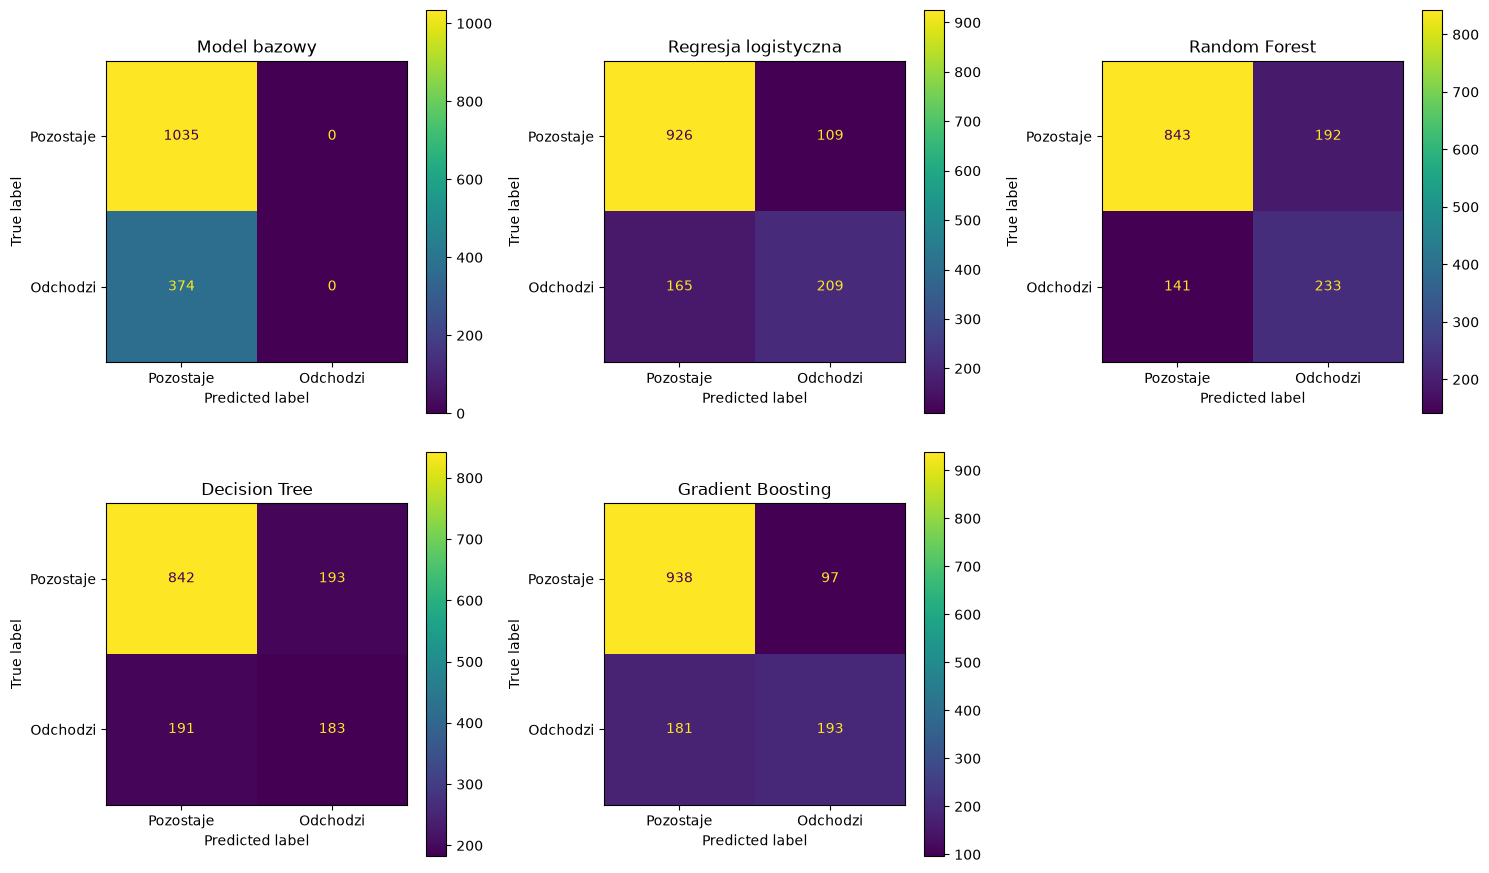

In [23]:
# ConfusionMatrixDisplay - wcześniej zaimportowane

# Lista modeli, które chcemy porównać
models = {
    "Model bazowy": baseline_model,
    "Regresja logistyczna": logistic_model,
    "Random Forest": random_forest_model,
    "Decision Tree": decision_tree_model,
    "Gradient Boosting": gradient_boosting_model
}

# Utworzenie wykresów
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Pozostaje", "Odchodzi"],
        cmap="viridis",
        values_format="d",
        ax=axes[i]
    )
    axes[i].set_title(name)

# Ukrycie pustego pola na szósty wykres
axes[5].axis("off")

plt.tight_layout()
plt.show()


#### Wnioski z analizy macierzy pomyłek

- **Model bazowy** nie wykrył żadnego klienta, który odszedł. Przewidywał pozostanie wszystkich klientów, dlatego mimo accuracy na poziomie 73,5% nie jest użyteczny do identyfikowania churnu.
- **Regresja logistyczna** poprawnie wykryła 209 z 374 klientów, którzy odeszli. Jednocześnie nie rozpoznała 165 odejść.
- **Random Forest** wykrył najwięcej odchodzących klientów — 233 z 374. Był jednak mniej precyzyjny: 192 klientów, których oznaczył jako odchodzących, faktycznie pozostało.
- **Decision Tree** wykrył 183 z 374 odchodzących klientów, co oznacza słabszy wynik niż w przypadku regresji logistycznej i Random Forest.
- **Gradient Boosting** poprawnie rozpoznał 193 odchodzących klientów. Spośród porównywanych modeli miał najmniej fałszywych alarmów dotyczących klientów, którzy ostatecznie pozostali — 97.

Wyniki pokazują, że modele różnią się nie tylko ogólną skutecznością, ale także rodzajem popełnianych błędów. W analizie churnu istotne jest zarówno wykrywanie klientów, którzy mogą odejść, jak i ograniczanie liczby fałszywych alarmów. Wybór najlepszego modelu zależy więc od tego, które z tych dwóch zadań ma większe znaczenie biznesowe.

#### **Zestawienie wyników modeli**

Aby ocenić skuteczność przetestowanych modeli, należy porównać ich wyniki za pomocą wybranych metryk: accuracy, precision, recall, F1-score oraz ROC-AUC.

Zestawienie pozwoli ocenić nie tylko ogólną skuteczność klasyfikacji, lecz także zdolność modeli do wykrywania klientów rezygnujących z usług. Wyniki stanowią podstawę do wskazania modelu najlepiej odpowiadającego celowi biznesowemu projektu.

In [24]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Nazwa modelu, przewidywania i wynik ROC-AUC
models_results = {
    "DummyClassifier": (y_pred_baseline, roc_auc_baseline),
    "Logistic Regression": (y_pred_logistic, roc_auc_logistic),
    "Random Forest": (y_pred_rf, roc_auc_rf),
    "Decision Tree": (y_pred_tree, roc_auc_tree),
    "Gradient Boosting": (y_pred_gb, roc_auc_gb)
}

results = []

for name, (y_pred, roc_auc) in models_results.items():

    # Macierz pomyłek: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc,
        "FN (przeoczone odejścia)": fn,
        "FP (fałszywe alarmy)": fp
    })

# Utworzenie i wyświetlenie tabeli
results_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
]

results_df[metric_columns] = results_df[metric_columns].round(3)

display(results_df)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN (przeoczone odejścia),FP (fałszywe alarmy)
0,DummyClassifier,0.735,0.000,0.000,0.000,0.500,374,0
1,Logistic Regression,0.806,0.657,0.559,0.604,0.842,165,109
2,Random Forest,0.764,0.548,0.623,0.583,0.824,141,192
3,Decision Tree,0.727,0.487,0.489,0.488,0.652,191,193
4,Gradient Boosting,0.803,0.666,0.516,0.581,0.843,181,97


### **Porównanie modeli klasyfikacyjnych**

Modele oceniono za pomocą pięciu metryk:

- **Accuracy** — odsetek poprawnych predykcji.
- **Precision** — jaka część klientów wskazanych jako zagrożeni odejściem rzeczywiście odeszła.
- **Recall** — jaka część wszystkich klientów, którzy odeszli, została wykryta przez model.
- **F1-score** — miara łącząca precision i recall.
- **ROC-AUC** — zdolność modelu do rozróżniania klientów odchodzących od pozostających; wynik 0,5 odpowiada poziomowi losowemu, a wynik bliższy 1 oznacza lepsze rozróżnianie.

Tabela zawiera również dwie wartości wynikające z macierzy pomyłek:

- **FN (False Negatives)** — liczba klientów, którzy odeszli, ale model nie przewidział ich odejścia.
- **FP (False Positives)** — liczba klientów, których model wskazał jako odchodzących, mimo że faktycznie pozostali.

Niższa liczba FN oznacza mniej przeoczonych odejść, a niższa liczba FP — mniej fałszywych alarmów. Znaczenie obu rodzajów błędów zależy od celu biznesowego.

#### Interpretacja wyników

- **DummyClassifier** — osiąga accuracy 0,735, ale nie wykrywa żadnego odejścia. Pokazuje, że samo accuracy nie wystarcza do oceny modelu w zadaniu przewidywania churnu.
- **Logistic Regression** — uzyskała najwyższe accuracy (0,81) i F1-score (0,60) wśród modeli wykorzystujących cechy klientów. Osiągnęła również wysoki ROC-AUC (0,842), co wskazuje na dobry kompromis między analizowanymi metrykami.
- **Random Forest** — osiągnął najwyższy recall (0,62), czyli wykrył największą część rzeczywistych odejść. Niższe precision (0,55) oznacza jednak więcej fałszywych alarmów niż w przypadku modeli o wyższym precision.
- **Decision Tree** — uzyskało słabsze wyniki niż pozostałe modele wykorzystujące cechy klientów: F1-score 0,49 i ROC-AUC 0,652. Jego zaletą jest możliwość prześledzenia reguł decyzyjnych.
- **Gradient Boosting** — osiągnął najwyższe precision (0,67) i ROC-AUC (0,843). Przewaga ROC-AUC nad Logistic Regression jest jednak minimalna, a recall wynosi 0,52.

#### Wnioski i wybór modelu

Na potrzeby tego projektu, biorąc pod uwagę jedynie przyjęte metryki, jako preferowany model można wskazać **regresję logistyczną**, ponieważ osiągnęła najwyższe accuracy i F1-score spośród modeli wykorzystujących cechy klientów, zachowując jednocześnie wysoki ROC-AUC.

Wybór zależy jednak od celu biznesowego. Jeśli priorytetem jest wykrycie jak największej liczby klientów zagrożonych odejściem, warto rozważyć Random Forest ze względu na najwyższy recall. Jeśli ważniejsze jest ograniczenie liczby fałszywych alarmów, interesującą alternatywą jest Gradient Boosting, który uzyskał najwyższe precision.

DummyClassifier pełni funkcję modelu bazowego, natomiast Decision Tree w tej konfiguracji osiągnęło słabsze wyniki.

##### Ograniczenia

Porównanie opiera się na jednym podziale danych na zbiór treningowy i testowy. Nie przeprowadzono pełnej optymalizacji hiperparametrów ani analizy kosztów biznesowych błędnych predykcji. Wyniki nie gwarantują więc identycznej skuteczności na nowych danych, a przed wdrożeniem należałoby dodatkowo ocenić dobór progu decyzyjnego i działanie modelu w praktyce.

------------------------------------------------

### Interpretacja cech — regresja logistyczna

Regresja logistyczna pozwala ocenić, jak poszczególne cechy wiążą się z przewidywanymi szansami churnu. Współczynniki dodatnie zwiększają, a ujemne zmniejszają logarytm tych szans, przy pozostałych cechach bez zmian. Nie oznaczają bezpośrednio zmiany prawdopodobieństwa w punktach procentowych.

Cechy liczbowe zostały wystandaryzowane, dlatego ich współczynniki odnoszą się do zmiany wartości cechy o jedno odchylenie standardowe. Cechy kategoryczne zakodowano metodą *one-hot encoding*, która przekształca kategorie, np. rodzaje umów, w wartości liczbowe wykorzystywane przez model.

Współczynniki opisują zależności wykryte przez model, nie dowodzą przyczynowości, a ich wielkości nie zawsze można bezpośrednio porównywać między różnymi typami cech.

In [25]:
# Pobranie nazw cech po preprocessingu i współczynników modelu
feature_names_lr = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficients_lr = logistic_model.named_steps["classifier"].coef_[0]

logistic_importance = pd.DataFrame({
    "Cecha": feature_names_lr,
    "Współczynnik": coefficients_lr
})

logistic_importance["Wartość bezwzględna"] = (
    logistic_importance["Współczynnik"].abs()
)

# Najsilniejsze współczynniki według wartości bezwzględnej
display(
    logistic_importance
    .sort_values("Wartość bezwzględna", ascending=False)
    .head(15)
    .round(3)
)


,Cecha,Współczynnik,Wartość bezwzględna
0,num__tenure,-1.255,1.255
39,cat__Contract_Two year,-0.759,0.759
17,cat__InternetService_Fiber optic,0.648,0.648
16,cat__InternetService_DSL,-0.644,0.644
1,num__MonthlyCharges,-0.601,0.601
37,cat__Contract_Month-to-month,0.586,0.586
2,num__TotalCharges,0.533,0.533
40,cat__PaperlessBilling_No,-0.331,0.331
26,cat__DeviceProtection_No internet service,-0.293,0.293
20,cat__OnlineSecurity_No internet service,-0.293,0.293


### Interpretacja cech — Random Forest

Random Forest składa się z wielu drzew decyzyjnych. Atrybut `feature_importances_` pozwala ocenić względną ważność poszczególnych cech na podstawie podziałów wykonywanych w drzewach modelu.

Ważność cechy nie wskazuje, czy wiąże się ona ze wzrostem, czy ze spadkiem ryzyka churnu, ani nie oznacza, że powoduje odejście klienta. Pokazuje jedynie, jak istotna była dla predykcji w ramach wyuczonego modelu.

In [26]:

# Pobranie nazw cech i ważności z Random Forest
feature_names_rf = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_rf = random_forest_model.named_steps[
    "classifier"
].feature_importances_

rf_importance = pd.DataFrame({
    "Cecha": feature_names_rf,
    "Ważność": importances_rf
})

display(
    rf_importance
    .sort_values("Ważność", ascending=False)
    .head(15)
    .round(4)
)


,Cecha,Ważność
2,num__TotalCharges,0.1406
0,num__tenure,0.1303
1,num__MonthlyCharges,0.1224
37,cat__Contract_Month-to-month,0.0645
39,cat__Contract_Two year,0.0392
19,cat__OnlineSecurity_No,0.0354
28,cat__TechSupport_No,0.0300
44,cat__PaymentMethod_Electronic check,0.0285
17,cat__InternetService_Fiber optic,0.0243
22,cat__OnlineBackup_No,0.0181


### Interpretacja cech — Decision Tree

Drzewo decyzyjne podejmuje decyzje poprzez kolejne podziały danych na podstawie wartości cech. Atrybut `feature_importances_` wskazuje względną ważność cech w tych podziałach.

W porównaniu z Random Forest pojedyncze drzewo jest łatwiejsze do prześledzenia, ale może być bardziej podatne na zmiany w danych. Sama tabela ważności nie pokazuje pełnych reguł decyzyjnych ani tego, czy dana cecha zwiększa, czy zmniejsza ryzyko churnu.

In [27]:

# Pobranie nazw cech i ważności z Decision Tree
feature_names_tree = decision_tree_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_tree = decision_tree_model.named_steps[
    "classifier"
].feature_importances_

tree_importance = pd.DataFrame({
    "Cecha": feature_names_tree,
    "Ważność": importances_tree
})

display(
    tree_importance
    .sort_values("Ważność", ascending=False)
    .head(15)
    .round(4)
)


,Cecha,Ważność
37,cat__Contract_Month-to-month,0.2340
1,num__MonthlyCharges,0.1726
2,num__TotalCharges,0.1639
0,num__tenure,0.1078
17,cat__InternetService_Fiber optic,0.0419
4,cat__gender_Male,0.0204
44,cat__PaymentMethod_Electronic check,0.0184
43,cat__PaymentMethod_Credit card (automatic),0.0156
28,cat__TechSupport_No,0.0145
40,cat__PaperlessBilling_No,0.0126


### Interpretacja cech — Gradient Boosting

Gradient Boosting buduje sekwencję drzew, w której kolejne modele starają się poprawiać błędy wcześniejszych. Atrybut `feature_importances_` pozwala ocenić względną ważność cech na podstawie podziałów w drzewach tworzących model.

Podobnie jak w Random Forest i Decision Tree, ważność nie wskazuje kierunku zależności ani nie dowodzi związku przyczynowego. Pokazuje jedynie, jakie znaczenie poszczególne cechy miały dla predykcji w ramach wyuczonego modelu.

In [28]:

# Pobranie nazw cech i ważności z Gradient Boosting
feature_names_gb = gradient_boosting_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_gb = gradient_boosting_model.named_steps[
    "classifier"
].feature_importances_

gb_importance = pd.DataFrame({
    "Cecha": feature_names_gb,
    "Ważność": importances_gb
})

display(
    gb_importance
    .sort_values("Ważność", ascending=False)
    .head(15)
    .round(4)
)

,Cecha,Ważność
37,cat__Contract_Month-to-month,0.3797
0,num__tenure,0.1422
17,cat__InternetService_Fiber optic,0.0861
2,num__TotalCharges,0.0853
1,num__MonthlyCharges,0.0806
19,cat__OnlineSecurity_No,0.0679
44,cat__PaymentMethod_Electronic check,0.0441
28,cat__TechSupport_No,0.0381
40,cat__PaperlessBilling_No,0.0120
13,cat__MultipleLines_No,0.0119


### **Porównanie interpretacji cech w modelach**

#### 1. Cechy wspólne

**Opłaty i długość relacji z klientem**

We wszystkich czterech modelach istotne były cechy liczbowe:
- `tenure` — długość korzystania z usług,
- `MonthlyCharges` — miesięczna opłata,
- `TotalCharges` — łączna kwota dotychczasowych opłat.

Wskazuje to, że długość relacji z operatorem i opłaty miały znaczenie dla przewidywania churnu. Modele oceniały je jednak na różne sposoby, dlatego uzyskanych miar nie należy porównywać bezpośrednio.

**Rodzaj umowy**

`Contract_Month-to-month` wyróżniał się wysoką ważnością we wszystkich trzech modelach drzewiastych: Random Forest, Decision Tree i Gradient Boosting. Szczególnie wyraźnie było to widoczne w Gradient Boosting, gdzie ważność tej cechy wyniosła **0,3797**.

#### 2. Różnice między modelami

- **Regresja logistyczna** — współczynnik dla `tenure` wskazywał na niższe przewidywane szanse odejścia przy dłuższym stażu klienta. Współczynniki związane z kategoriami Contract wskazywały na różnice między rodzajami umów, przy czym ich interpretacja wymaga uwzględnienia zastosowanego kodowania zmiennych kategorycznych.
- **Random Forest** — największą ważność przypisał `TotalCharges`, `tenure` i `MonthlyCharges`. Znaczenie miały również m.in. rodzaj umowy, brak wybranych usług dodatkowych i metoda płatności.
- **Decision Tree** — największą ważność przypisał `Contract_Month-to-month`, a następnie `MonthlyCharges`, `TotalCharges` i `tenure`.
- **Gradient Boosting** — wyraźnie wyróżnił `Contract_Month-to-month` na tle pozostałych cech.

**Ograniczenia interpretacji:** ważność cechy nie dowodzi związku przyczynowego ani określonego procentowego wpływu na churn. Ponadto wartości ważności nie są bezpośrednio porównywalne między różnymi typami modeli - współczynników regresji logistycznej nie można bezpośrednio porównywać z miarami ważności cech w modelach drzewiastych, ponieważ opisują inne aspekty działania modeli.

----------

### **Wnioski biznesowe**

#### 1. Możliwość przewidywania odejść klientów

Przetestowane modele wykazały, że na podstawie dostępnych danych można przewidywać odejścia klientów skuteczniej niż za pomocą prostego modelu bazowego, który zakłada brak odejścia każdego klienta, np. regresja logistyczna osiągnęła accuracy na poziomie 80,6%, wobec 73,5% dla modelu bazowego.

Wyniki wskazują, że analiza danych może wspierać działania operatora mające na celu utrzymanie klientów. Nie oznacza to jednak, że model bezbłędnie identyfikuje klientów zagrożonych odejściem — każdy z przetestowanych modeli popełniał błędy.

#### 2. Znaczenie cech związanych z relacją z klientem

Interpretacja cech wskazuje na znaczenie długości korzystania z usług, wysokości opłat oraz rodzaju umowy. Szczególnie wyróżniała się umowa miesięczna, której modelom drzewiastym przypisano wysoką ważność.

Wyniki te sugerują, że warto dokładniej analizować zachowania klientów korzystających z umów miesięcznych oraz klientów na wczesnym etapie relacji z operatorem. Są to jednak wskazówki do dalszej analizy, a nie dowód, że same te cechy powodują odejście.

#### 3. Dobór modelu zależy od celu biznesowego

Nie istnieje jeden model, który musi być najlepszy pod każdym względem. Regresja logistyczna zapewniła dobry kompromis między wykrywaniem odejść a ograniczaniem fałszywych alarmów. Random Forest wykrył większą część klientów, którzy faktycznie odeszli, osiągając recall na poziomie 62,3%. Gradient Boosting uzyskał najwyższy ROC-AUC (0,843), ale wynik ten był niemal identyczny jak w przypadku regresji logistycznej (0,842).

W praktyce wybór powinien uwzględniać koszty obu rodzajów błędów. Przeoczenie klienta, który odejdzie, może oznaczać utratę przychodu, natomiast błędne wskazanie klienta jako zagrożonego odejściem może prowadzić do niepotrzebnych rabatów lub innych kosztownych działań.

#### 4. Rekomendowane dalsze działania

Wyniki projektu można wykorzystać jako punkt wyjścia do dalszych prac nad strategią utrzymania klientów. Warto w szczególności:

- przeanalizować przyczyny odejść w grupach klientów wskazanych jako bardziej narażone na churn;
- sprawdzić, czy działania retencyjne rzeczywiście ograniczają liczbę odejść i czy ich koszt jest uzasadniony;
- przetestować modele na nowych danych oraz ocenić ich skuteczność w warunkach zbliżonych do rzeczywistego zastosowania;
- dobrać próg klasyfikacji do kosztów działań retencyjnych i konsekwencji niewykrycia odejścia.

Wyniki analizy mogą wspierać podejmowanie decyzji, ale nie zastępują oceny opłacalności działań ani dalszej walidacji modelu.

## **Podsumowanie projektu**

Celem projektu było zbudowanie i porównanie modeli uczenia maszynowego służących do przewidywania odejść klientów operatora telekomunikacyjnego (*customer churn*).

Porównano pięć modeli: Dummy Classifier, regresję logistyczną, Random Forest, Decision Tree oraz Gradient Boosting. Ich skuteczność oceniono za pomocą kilku metryk, w tym accuracy, precision, recall, F1-score i ROC-AUC.

Najważniejsze rezultaty:

- **Regresja logistyczna** uzyskała najwyższy F1-score spośród analizowanych modeli predykcyjnych (0,604) oraz accuracy na poziomie 80,6%.
- **Random Forest** osiągnął najwyższy recall (0,623), wykrywając największą część klientów, którzy faktycznie odeszli.
- **Gradient Boosting** uzyskał najwyższe precision (0,666) i ROC-AUC (0,843), jednak jego przewaga w ROC-AUC nad regresją logistyczną była niewielka.
- **Decision Tree** osiągnęło słabsze wyniki, a **Dummy Classifier** pokazał, że wysoka accuracy sama w sobie nie wystarcza do oceny modelu w zadaniu przewidywania churnu.

Wyniki wskazują, że wybór modelu powinien zależeć od celu biznesowego i konsekwencji błędów klasyfikacji. 

W analizowanym przypadku warto rozważyć przede wszystkim regresję logistyczną i Random Forest. Regresja logistyczna zapewniła zrównoważony kompromis między wykrywaniem odejść a ograniczaniem fałszywych alarmów, natomiast Random Forest wykrył większą część klientów, którzy faktycznie odeszli. 

Ostateczny wybór powinien uwzględniać koszty działań retencyjnych oraz konsekwencje niewykrycia klienta zagrożonego odejściem.

### Ograniczenia i potencjalne rozwinięcie projektu

Przeprowadzona analiza ma kilka ograniczeń:

- Modele oceniono na jednym podziale danych treningowych i testowych.
- Nie przeprowadzono szerokiego strojenia hiperparametrów.
- Nie analizowano szczegółowo kosztów biznesowych poszczególnych rodzajów błędów.
- Nie sprawdzono, czy wyniki utrzymują się na nowych danych.
- Ważność cech i współczynniki modeli nie dowodzą związku przyczynowego.

W przyszłości warto przetestować różne progi klasyfikacji, przeprowadzić walidację krzyżową oraz porównać modele z uwzględnieniem kosztów działań utrzymaniowych i utraconych klientów.